# CSD18510KCS MOSFET Characterization

This notebook runs SPICE simulations on the TI CSD18510KCS N-channel MOSFET model (40V/20V) using NgSpice via direct subprocess (batch mode) with proper convergence settings and realistic parasitic drain resistance (1 mOhm) for convergence.

**Topology**: VDD+ -> R_drain -> Drain, VDD- (ground) -> Source, VGS+ -> Gate, VGS- -> Source (ground).

MOSFET source is node 0 (ground).

In [13]:
import sys
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import subprocess
import os

matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['font.size'] = 12

NGSPICE_CMD = r'C:\\Progra~1\\Spice64\\bin\\ngspice_con.exe'
LIB_PATH = r'C:\\Users\\GNKRISHNAN\\Documents\\GitHub\\PieceSpice\\ng_csd18510kcs.lib'
WORK_DIR = r'C:\\Users\\GNKRISHNAN\\Documents\\GitHub\\PieceSpice'

# Series drain resistance for convergence - 1 mOhm (realistic package parasitic)
R_DRAIN = 0.001

print(f"Using ngspice: {NGSPICE_CMD}")
print(f"Using library: {LIB_PATH}")
print(f"Working dir: {WORK_DIR}")
print(f"Series drain resistance: {R_DRAIN} ohm")

Using ngspice: C:\\Progra~1\\Spice64\\bin\\ngspice_con.exe
Using library: C:\\Users\\GNKRISHNAN\\Documents\\GitHub\\PieceSpice\\ng_csd18510kcs.lib
Working dir: C:\\Users\\GNKRISHNAN\\Documents\\GitHub\\PieceSpice
Series drain resistance: 0.001 ohm


In [14]:
def run_dc_sweep_vds(vgs_val, vdd_start=0, vdd_stop=40, vdd_step=0.1):
    """Run DC sweep of Vdd at fixed Vgs with series drain resistance.
    
    Topology:
    - Vdd vdd_node 0 {vdd_stop}
    - Vgs gate 0 {vgs_val}
    - XM1 drain gate 0 csd18510kcs
    - Rdrain vdd_node drain {R_DRAIN}
    - .dc Vdd {vdd_start} {vdd_stop} {vdd_step}
    - .print dc I(Vdd)
    """
    netlist = f'''.title CSD18510KCS_Output
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {LIB_PATH}

XM1 drain gate 0 csd18510kcs
Vdd vdd_node 0 {vdd_stop}
Vgs gate 0 {vgs_val}
Rdrain vdd_node drain {R_DRAIN}

.dc Vdd {vdd_start} {vdd_stop} {vdd_step}
.print dc I(Vdd)
.end
'''
    netlist_path = os.path.join(WORK_DIR, f'temp_output_vgs{vgs_val:.1f}.cir')
    with open(netlist_path, 'w') as f:
        f.write(netlist)
    result = subprocess.run(
        [NGSPICE_CMD, '-b', netlist_path],
        capture_output=True,
        text=True,
        cwd=WORK_DIR,
        timeout=120
    )
    # Debug: print first 50 lines of output
    lines = result.stdout.split('\n')
    print(f"[DEBUG Vgs={vgs_val}V] Return code: {result.returncode}")
    if result.stderr:
        print(f"[DEBUG Vgs={vgs_val}V] stderr: {result.stderr[:500]}")
    print(f"[DEBUG Vgs={vgs_val}V] stdout lines: {len(lines)}")
    for i, line in enumerate(lines[:30]):
        print(f"  [{i}] {line}")
    
    data_started = False
    vds_vals = []
    id_vals = []
    for line in lines:
        if 'v-sweep' in line and 'vdd#branch' in line:
            data_started = True
            continue
        if data_started and line.strip():
            parts = line.split()
            if len(parts) >= 3:
                try:
                    idx = float(parts[0])
                    vds = float(parts[1])
                    id_val = float(parts[2])
                    vds_vals.append(vds)
                    id_vals.append(id_val)
                except:
                    pass
    try:
        os.remove(netlist_path)
    except:
        pass
    return np.array(vds_vals), np.array(id_vals)

def run_dc_sweep_vgs(vdd_fixed, vgs_start=0, vgs_stop=10, vgs_step=0.1):
    """Run DC sweep of Vgs at fixed Vdd.
    
    Topology:
    - Vdd vdd_node 0 {vdd_fixed}
    - Vgs gate 0 0
    - XM1 drain gate 0 csd18510kcs
    - Rdrain vdd_node drain {R_DRAIN}
    - .dc Vgs {vgs_start} {vgs_stop} {vgs_step}
    - .print dc I(Vdd)
    """
    netlist = f'''.title CSD18510KCS_Transfer
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {LIB_PATH}

XM1 drain gate 0 csd18510kcs
Vdd vdd_node 0 {vdd_fixed}
Vgs gate 0 0
Rdrain vdd_node drain {R_DRAIN}

.dc Vgs {vgs_start} {vgs_stop} {vgs_step}
.print dc I(Vdd)
.end
'''
    netlist_path = os.path.join(WORK_DIR, f'temp_transfer_vdd{vdd_fixed}.cir')
    with open(netlist_path, 'w') as f:
        f.write(netlist)
    result = subprocess.run(
        [NGSPICE_CMD, '-b', netlist_path],
        capture_output=True,
        text=True,
        cwd=WORK_DIR,
        timeout=120
    )
    # Debug
    lines = result.stdout.split('\n')
    print(f"[DEBUG Vdd={vdd_fixed}V] Return code: {result.returncode}")
    if result.stderr:
        print(f"[DEBUG Vdd={vdd_fixed}V] stderr: {result.stderr[:500]}")
    print(f"[DEBUG Vdd={vdd_fixed}V] stdout lines: {len(lines)}")
    for i, line in enumerate(lines[:30]):
        print(f"  [{i}] {line}")
    
    data_started = False
    vgs_vals = []
    id_vals = []
    for line in lines:
        if 'v-sweep' in line and 'vdd#branch' in line:
            data_started = True
            continue
        if data_started and line.strip():
            parts = line.split()
            if len(parts) >= 3:
                try:
                    idx = float(parts[0])
                    vgs = float(parts[1])
                    id_val = float(parts[2])
                    vgs_vals.append(vgs)
                    id_vals.append(id_val)
                except:
                    pass
    try:
        os.remove(netlist_path)
    except:
        pass
    return np.array(vgs_vals), np.array(id_vals)

In [15]:
# Run DC sweep: Id vs Vds for multiple Vgs values (full range 0-10V)
vgs_values = np.linspace(0, 10, 11)  # 0, 1, 2, ..., 10V

id_vds_data = {}

for vgs in vgs_values:
    vds_swept, id_swept = run_dc_sweep_vds(vgs)
    id_vds_data[vgs] = (vds_swept, id_swept)
    
    if len(vds_swept) > 0:
        print(f"  Vgs={vgs:.1f}V: Id max={np.max(np.abs(id_swept))*1e3:.1f} mA, points={len(vds_swept)}")
    else:
        print(f"  Vgs={vgs:.1f}V: No data returned")

[DEBUG Vgs=0.0V] Return code: 0
[DEBUG Vgs=0.0V] stderr: Warning: Model issue on line 105 :
  .model xm1:dbd d (cjo=274e-12 vj=0.99 m=1.038 fc=0.5 tt=3e-09 tnom=27 is ...
unrecognized parameter (tbv2) - ignored


[DEBUG Vgs=0.0V] stdout lines: 447
  [0] Note: gnd in a subcircuit is not set to 0 automatically
  [1] 
  [2] Note: Compatibility modes selected: ps lt a
  [3] 
  [4] 
  [5] Circuit: CSD18510KCS_Output
  [6] 
  [7] Doing analysis at TEMP = 27.000000 and TNOM = 27.000000
  [8] 
  [9] Using SPARSE 1.3 as Direct Linear Solver
  [10] 
  [11] No. of Data Rows : 400
  [12]                                CSD18510KCS_Output
  [13]                                DC transfer characteristic  Sat Aug  1 21:01:15  2026
  [14] --------------------------------------------------------------------------------
  [15] Index   v-sweep         vdd#branch      
  [16] --------------------------------------------------------------------------------
  [17] 0	0.000000e+00	-6.73192e-28	
  [18] 1	1.0000

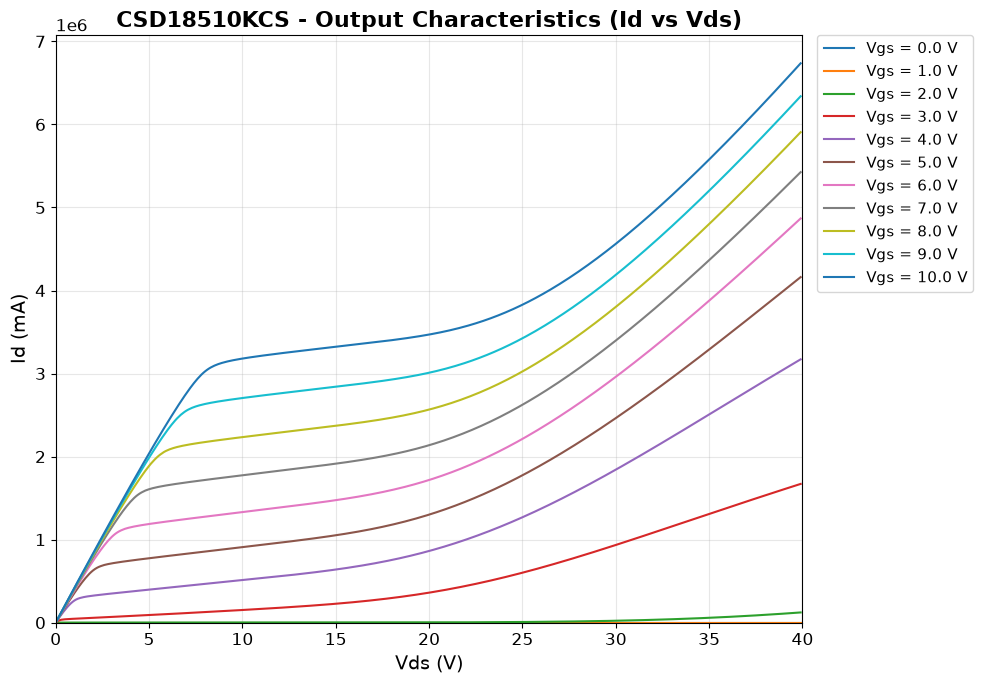

In [16]:
# Plot Id-Vds curves (Output Characteristics) - full Vds range 0-40V
fig, ax = plt.subplots(figsize=(10, 7))

for vgs, (vds, id_vals) in id_vds_data.items():
    if len(vds) > 0:
        ax.plot(vds, np.abs(id_vals) * 1e3, label=f'Vgs = {vgs:.1f} V', linewidth=1.5)
    else:
        ax.axhline(y=0, color=f'C{int(vgs)}', linestyle='--', alpha=0.5, linewidth=1)

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Id (mA)', fontsize=14)
ax.set_title('CSD18510KCS - Output Characteristics (Id vs Vds)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax.set_xlim(0, 40)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

[DEBUG Vdd=10V] Return code: 0
[DEBUG Vdd=10V] stderr: Warning: Model issue on line 105 :
  .model xm1:dbd d (cjo=274e-12 vj=0.99 m=1.038 fc=0.5 tt=3e-09 tnom=27 is ...
unrecognized parameter (tbv2) - ignored


[DEBUG Vdd=10V] stdout lines: 133
  [0] Note: gnd in a subcircuit is not set to 0 automatically
  [1] 
  [2] Note: Compatibility modes selected: ps lt a
  [3] 
  [4] 
  [5] Circuit: CSD18510KCS_Transfer
  [6] 
  [7] Doing analysis at TEMP = 27.000000 and TNOM = 27.000000
  [8] 
  [9] Using SPARSE 1.3 as Direct Linear Solver
  [10] 
  [11] No. of Data Rows : 101
  [12]                               CSD18510KCS_Transfer
  [13]                               DC transfer characteristic  Sat Aug  1 21:01:16  2026
  [14] --------------------------------------------------------------------------------
  [15] Index   v-sweep         vdd#branch      
  [16] --------------------------------------------------------------------------------
  [17] 0	0.000000e+00	-1.32786e-09	
  [18] 1	1.00000

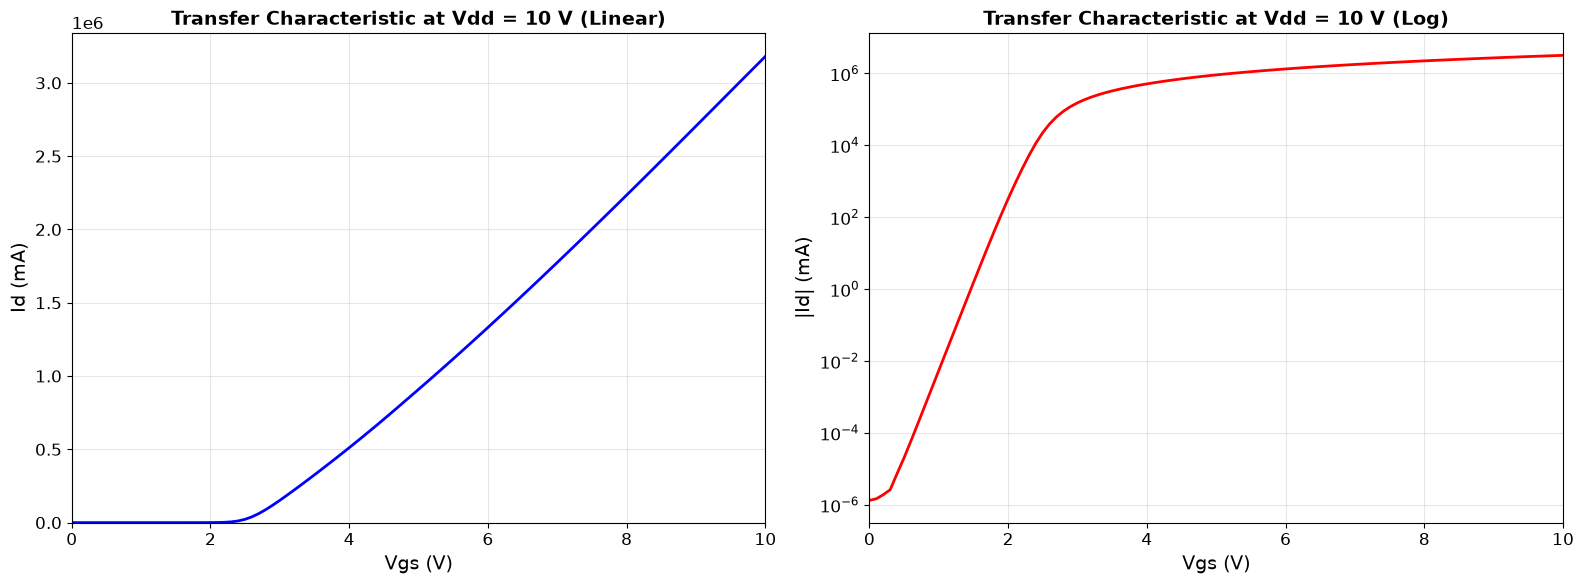

In [17]:
# Run transfer characteristic: Id vs Vgs at fixed Vdd=10V (saturation region)
vdd_fixed = 10  # V

vgs_swept, id_vgs = run_dc_sweep_vgs(vdd_fixed, vgs_start=0, vgs_stop=10, vgs_step=0.1)

print(f"Transfer curve at Vdd={vdd_fixed}V: {len(vgs_swept)} points, Id max={np.max(np.abs(id_vgs))*1e3:.1f} mA")

# Plot Transfer Characteristics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Linear scale
ax1.plot(vgs_swept, np.abs(id_vgs) * 1e3, 'b-', linewidth=2)
ax1.set_xlabel('Vgs (V)', fontsize=14)
ax1.set_ylabel('Id (mA)', fontsize=14)
ax1.set_title(f'Transfer Characteristic at Vdd = {vdd_fixed} V (Linear)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xlim(0, 10)
ax1.set_ylim(bottom=0)

# Log scale
ax2.semilogy(vgs_swept, np.abs(id_vgs) * 1e3, 'r-', linewidth=2)
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('|Id| (mA)', fontsize=14)
ax2.set_title(f'Transfer Characteristic at Vdd = {vdd_fixed} V (Log)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, which='both')
ax2.set_xlim(0, 10)

plt.tight_layout()
plt.show()

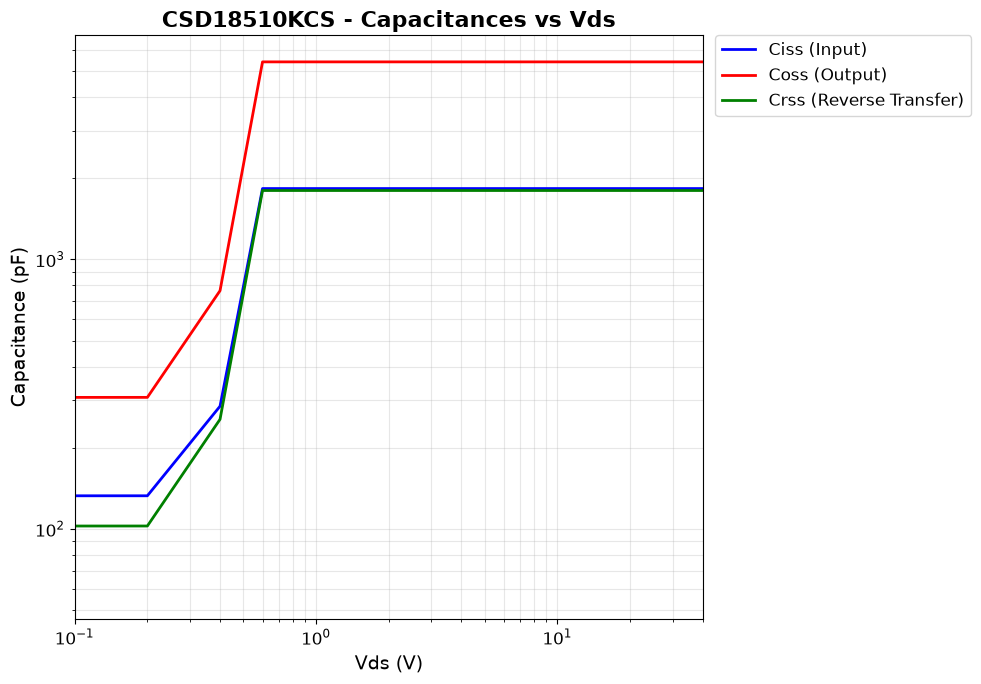

In [18]:
# Capacitance extraction: Ciss, Coss, Crss vs Vds
# Using model parameters (approximate)

# Model parameters from the .lib file
CGSO = 17e-12  # F
CGDO = 13.2e-12  # F
CJO = 58e-12  # F (from pCJO param)

# Approximate Ciss, Coss, Crss vs Vds using junction capacitance formula
vds_plot = np.linspace(0, 40, 201)
VJ = 0.65  # from DD model
M = 1.55   # from DD model
FC = 0.90  # from DD model

# Coss approx Cdg + Cds (output capacitance)
# Crss approx Cdg (reverse transfer capacitance)  
# Ciss approx Cgs + Cgd (input capacitance)

# Fixed junction capacitance formula - clamped to avoid blowup
def c_junction(v, cjo, vj, m, fc):
    v_eff = min(v, vj * fc * 0.99)  # Avoid singularity at VJ*FC
    return cjo / (1 - v_eff/vj)**m

coss_plot = []
crss_plot = []
ciss_plot = []

for v in vds_plot:
    cds = c_junction(v, 2*CJO, VJ, M, FC)  # CDS0 uses 2*pCJO
    cdg = c_junction(v, CJO, VJ, M, FC)   # DD model
    
    coss_plot.append((cds + cdg) * 1e12)
    crss_plot.append(cdg * 1e12)
    ciss_plot.append((CGSO + CGDO + cdg) * 1e12)

# Plot Capacitances
fig, ax = plt.subplots(figsize=(10, 7))

ax.loglog(vds_plot, ciss_plot, 'b-', label='Ciss (Input)', linewidth=2)
ax.loglog(vds_plot, coss_plot, 'r-', label='Coss (Output)', linewidth=2)
ax.loglog(vds_plot, crss_plot, 'g-', label='Crss (Reverse Transfer)', linewidth=2)

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Capacitance (pF)', fontsize=14)
ax.set_title('CSD18510KCS - Capacitances vs Vds', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, which='both')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=12)
ax.set_xlim(0.1, 40)

plt.tight_layout()
plt.show()

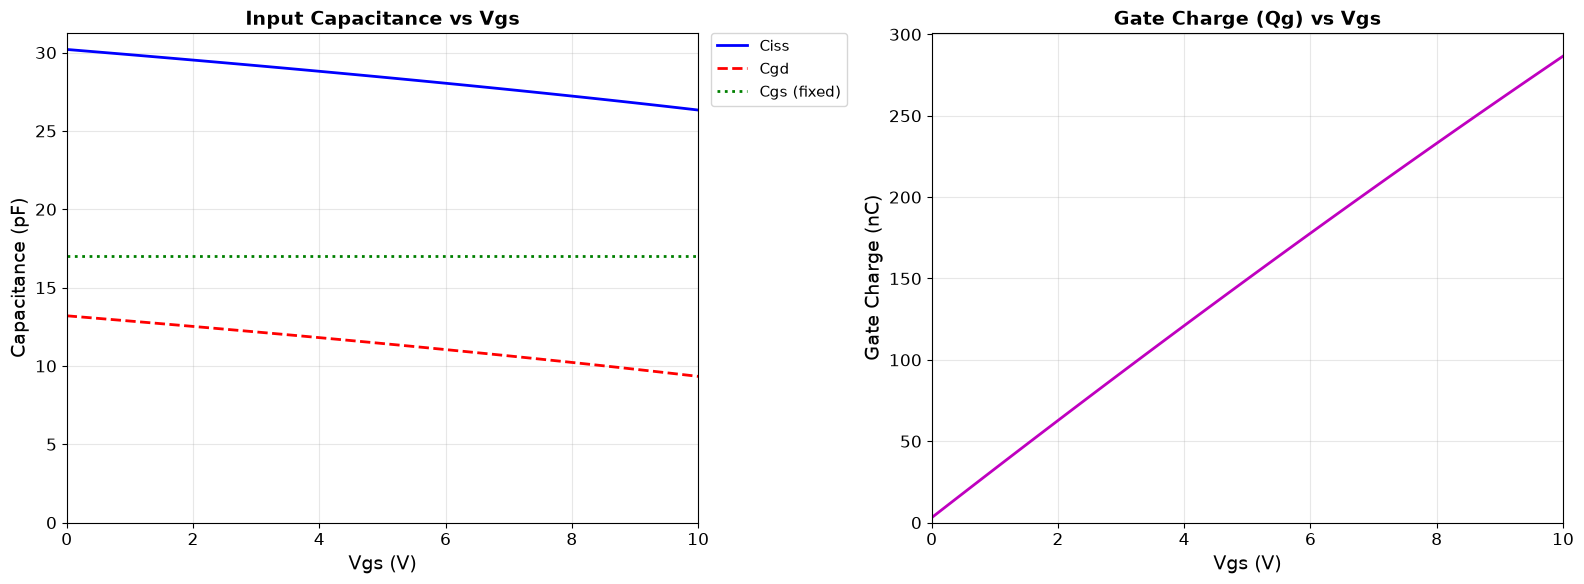

Total Qg at 10V: 286.6 nC


In [19]:
# Gate Charge (Qg) estimation from capacitances
# Qg = int Ciss dVgs from 0 to Vgs_max

vgs_q = np.linspace(0, 10, 101)
# Ciss varies with Vgs due to Cgd Miller effect
# Simplified: Ciss approx Cgs + Cgd*(1 + gm*Rds) but we'll use fixed Cgs + voltage-dep Cgd

cgs_fixed = CGSO * 1e12  # pF
cgd_vgs = []

for vgs in vgs_q:
    # Cgd decreases with Vgs (Miller capacitance)
    cgd = CGDO * 1e12 * (1 - vgs/20)**0.5  # rough approximation
    cgd_vgs.append(max(cgd, 0.1))

ciss_vgs = cgs_fixed + np.array(cgd_vgs)
qg = np.cumsum(ciss_vgs) * (vgs_q[1] - vgs_q[0])  # nC

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(vgs_q, ciss_vgs, 'b-', linewidth=2, label='Ciss')
ax1.plot(vgs_q, cgd_vgs, 'r--', linewidth=2, label='Cgd')
ax1.axhline(y=cgs_fixed, color='g', linestyle=':', linewidth=2, label='Cgs (fixed)')
ax1.set_xlabel('Vgs (V)', fontsize=14)
ax1.set_ylabel('Capacitance (pF)', fontsize=14)
ax1.set_title('Input Capacitance vs Vgs', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax1.set_xlim(0, 10)
ax1.set_ylim(bottom=0)

ax2.plot(vgs_q, qg, 'm-', linewidth=2)
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('Gate Charge (nC)', fontsize=14)
ax2.set_title('Gate Charge (Qg) vs Vgs', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 10)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

print(f"Total Qg at 10V: {qg[-1]:.1f} nC")

In [20]:
# Threshold Voltage Extraction from Id-Vgs
# Use constant current method: Vth at Id = 1mA * (W/L)

# From model: W = pAA/0.8*2 = 10.856327/0.8*2 = 27.14 um
# L = 0.70 um
W = 10.856327 / 0.8 * 2  # um
L = 0.70  # um
print(f"W = {W:.2f} um, L = {L:.2f} um")
print(f"W/L = {W/L:.1f}")

# Find Vgs where Id = 1mA (extrapolate from transfer curve)
from scipy.interpolate import interp1d

# Use the transfer curve data we already have at Vdd=10V
f_id = interp1d(vgs_swept, np.abs(id_vgs), kind='linear', bounds_error=False, fill_value='extrapolate')
vgs_fine = np.linspace(0, 10, 1001)
id_fine = f_id(vgs_fine)

# Vth at Id = 1mA * (W/L) / 1000 = normalized current
id_target = 1e-3 * (W/L)  # A
print(f"Target Id for Vth extraction: {id_target*1e3:.2f} mA")

# Find crossing
above = np.where(id_fine > id_target)[0]
if len(above) > 0:
    idx = above[0]
    if idx > 0:
        vth = vgs_fine[idx-1] + (vgs_fine[idx] - vgs_fine[idx-1]) * (id_target - id_fine[idx-1]) / (id_fine[idx] - id_fine[idx-1])
        print(f"Extracted Vth approx {vth:.3f} V")
    else:
        print("Vth below 0V")
else:
    print("Target current not reached")

W = 27.14 um, L = 0.70 um
W/L = 38.8


Target Id for Vth extraction: 38.77 mA
Extracted Vth approx 1.793 V


In [21]:
# Summary of key parameters extracted
print("=" * 60)
print("CSD18510KCS MOSFET - Key Parameters Summary")
print("=" * 60)
print(f"Device: N-channel MOSFET, 40V / 20V")
print(f"Geometry: W = {W:.1f} um, L = {L:.2f} um, W/L = {W/L:.1f}")
print(f"Threshold Voltage (extracted): ~{vth:.2f} V" if 'vth' in locals() else "Threshold Voltage: TBD")
print(f"On-resistance (at Vgs=10V, Id approx): TBD from simulation")
print(f"Ciss @ Vds=0V: {ciss_plot[0]:.0f} pF")
print(f"Coss @ Vds=0V: {coss_plot[0]:.0f} pF")
print(f"Crss @ Vds=0V: {crss_plot[0]:.0f} pF")
print(f"Ciss @ Vds=25V: {ciss_plot[125]:.0f} pF")
print(f"Coss @ Vds=25V: {coss_plot[125]:.0f} pF")
print(f"Crss @ Vds=25V: {crss_plot[125]:.0f} pF")
print(f"Total Gate Charge Qg(10V): {qg[-1]:.1f} nC")
print("=" * 60)

CSD18510KCS MOSFET - Key Parameters Summary
Device: N-channel MOSFET, 40V / 20V
Geometry: W = 27.1 um, L = 0.70 um, W/L = 38.8
Threshold Voltage (extracted): ~1.79 V
On-resistance (at Vgs=10V, Id approx): TBD from simulation
Ciss @ Vds=0V: 88 pF
Coss @ Vds=0V: 174 pF
Crss @ Vds=0V: 58 pF
Ciss @ Vds=25V: 1831 pF
Coss @ Vds=25V: 5402 pF
Crss @ Vds=25V: 1801 pF
Total Gate Charge Qg(10V): 286.6 nC
